# C0 · ISBI 2015 · Medium tier (UNet-32) · arm A: equal-area ovals along (A∥) and across (A⊥) the baseline error axis

**Experiment plan:** MDT experiment plan C0 "Transfer", §4.2 arm table (A∥, A⊥), §4.3 axis rule, §5 Q1, §6 P0a/P0b and P0e (capacity).
This is the second capacity point: the same 24 oval runs as at High, so α can be compared between the High and Medium tiers (Q5).

**What arm A is.** Every landmark gets an oval Gaussian target with the round baseline's area: axes σ₀√r and σ₀/√r for aspect ratio
r = 1.5, 2, 3, 4. In **A∥** the long axis lies along that landmark's baseline error axis; in **A⊥** it lies across it, so target and
image disagree. All 19 landmarks share r within a run.

**σ₀ for this tier is 7.07 px (2.21 mm), not 5 px.** Medium arm R lost landmarks at 5 px (gross failures 4.3–18.7 % across the five
1 × σ₀ runs) and works from 7.07 px. With the tier-level rule (σ₀ = narrowest round width at which every paired run stays ≤ 5 %),
σ₀ moves to 1.41 × the High value. The paired round baselines are the existing arm R runs `C0_ISBI2015_Medium_R_w1.41_s{1,2,3}`.

**Frozen inputs from arm R (same tier).** The baseline axes are the major-axis angles of the fine-scatter errors of this tier's two
axis-definition runs (`w1.00_s101`, `w1.00_s102`, the same run ids as at High), frozen in `baseline_axes_ISBI2015_Medium.csv` and
embedded in §3 with the file's SHA-256, so training needs no arm R files. **Deviation from the axis rule (logged):** those two runs were
trained at the provisional 5 px, not at σ₀ = 7.07 px. They lost porion, gonion, posterior nasal spine and articulare in about half the
test images, but the axes use only the fine scatter after the 4 mm cut. Diagnostic check before this notebook was built: on the 17
landmarks with a defined axis, the 5 px axis directions agree with the 7.07 px round runs within a median of 1.3° (maximum 11.4°,
upper incisal incision, SD ratio 1.37). Sella has no defined axis (SD ratio < 1.15): its ovals use the image x-axis, it counts for α
and is left out of the disagreement subset (P0b).

**Pairing.** Seeds 1–3 are the seeds of the arm R runs and augmentation comes from `default_rng([seed, epoch, index])`, so each oval run
sees exactly the images, augmentations and batch order of its paired round baseline; only the target differs. `PROTOCOL` is the Medium
arm R protocol (hash 09b9ae2a23fe2266); the oval specification, including the frozen axes, has its own `ARM_HASH`.

**Short axes and the detectability floor.** At σ₀ = 7.07 px the ovals are 8.7 × 5.8, 10.0 × 5.0, 12.2 × 4.1 and 14.1 × 3.5 px for
r = 1.5, 2, 3, 4. Round targets at Medium failed at 5 px and badly at 3.5 px; at High, ratio-4 ovals trained normally although their
2.5 px short axis failed as a round target, because failure followed overall target size. Whether this also holds at Medium is one of
this arm's results. The first wave of the six GPU copies holds all four seed-1 runs at ratios 4 and 3.

**Run count.** 2 orientations × 4 ratios × 3 seeds = **24 runs**, about 1.4 h each with six notebooks on a 2-GPU pod (four waves,
≈ 5.6 h wall time).

**Section 10** needs the paired B0 runs `C0_ISBI2015_Medium_R_w1.41_s{1,2,3}` in the same `RUN_ROOT` (and, for the separability check,
`w1.00` and `w2.00`). On a pod that trained only arm A, copy them there (DONE, config.json, summary_final.csv, predictions_test.csv.gz)
or run §10 locally next to the arm R runs.

> **GPU 0, notebook 3 of 3 on this GPU: 4 oval runs (one per wave).** Identical to `C0_ISBI2015_Medium_A.ipynb` except for `RUN_IDS`, `NUM_WORKERS` and `GPU` in the parameters cell; none of them is part of `PROTOCOL` or `ARM_SPEC`, so all six notebooks share one protocol hash and one arm hash. Start all six at the same time in a 2-GPU pod, each in its own kernel, with the **same `RUN_ROOT`** (the arm R folder of this tier). If you change `GPU`, restart the kernel first. The arm-level analysis (§10) runs once, in whichever notebook finishes last, provided the paired arm R B0 runs are in `RUN_ROOT`.

In [1]:
import os

DATASET = "ISBI 2015"
TIER = "Medium"
ARM = "A"

RUN_IDS = ["C0_ISBI2015_Medium_Apar_r2.00_s1", "C0_ISBI2015_Medium_Aperp_r3.00_s2", "C0_ISBI2015_Medium_Apar_r4.00_s3", "C0_ISBI2015_Medium_Aperp_r1.50_s3"]   # this notebook's share of the run table
SMOKE_TEST = False      # True: synthetic data, tiny UNet, 4 epochs; checks the pipeline only, results meaningless

DATA_ROOT = os.environ.get("ISBI_ROOT", "/tf/data/ISBI2015")
# Runs go to the persistent RunPod volume (/workspace) when it exists; the container disk is wiped when the pod stops.
# All notebooks that share runs (e.g. the part 1-3 copies) must use the same RUN_ROOT.
RUN_ROOT = os.environ.get("C0_RUN_ROOT", "/workspace/C0/ISBI2015_Medium" if os.path.isdir("/workspace")
                          else "/tf/weights/C0/ISBI2015_Medium")

SIGMA0_PX = 5.0 * 2 ** 0.5   # σ₀ of this tier, 7.07 px (2.21 mm): the narrowest round width at which every paired
                             # Medium arm R run stays at <= 5 % gross failures (1.41 x the High sigma0)
EPOCHS = 800
BATCH_SIZE = 4
NUM_WORKERS = 3         # 6 notebooks run at once: 6 x 3 data workers
GPU = 0                 # physical GPU used by this notebook
PROGRESS_BAR = True     # one progress bar per run, advanced every epoch (loss, training-subset MRE, s/epoch, ETA)

## 0. Setup and frozen protocol

In [2]:
import sys
if GPU is not None:
    # must happen before PyTorch initialises CUDA in this kernel
    if "torch" in sys.modules and sys.modules["torch"].cuda.is_initialized():
        raise RuntimeError("GPU can only be chosen before PyTorch starts: restart the kernel and run from the top.")
    os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU)
import json, math, re, time, hashlib, platform, subprocess, warnings, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

cv2.setNumThreads(0)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    # Fail fast if this PyTorch build has no kernels for the GPU (e.g. Blackwell sm_120 with a cu121/cu124 wheel)
    _maj, _min = torch.cuda.get_device_capability(0)
    _arch, _built = f"sm_{_maj}{_min}", torch.cuda.get_arch_list()
    if _arch not in _built:
        raise RuntimeError(f"{torch.cuda.get_device_name(0)} is {_arch}, but this PyTorch {torch.__version__} "
                           f"(CUDA {torch.version.cuda}) only has kernels for {_built}. For Blackwell (sm_120) install "
                           "PyTorch >= 2.7 built for CUDA >= 12.8, e.g. pip install --upgrade torch torchvision "
                           "--index-url https://download.pytorch.org/whl/cu128, then restart the kernel.")
    _ = (torch.ones(256, 256, device=DEVICE) @ torch.ones(256, 256, device=DEVICE)).sum().item()
if GPU is not None and DEVICE.type == "cuda":
    assert torch.cuda.device_count() == 1, f"expected only GPU {GPU} to be visible, got {torch.cuda.device_count()}"
if os.name == "nt" or SMOKE_TEST:
    NUM_WORKERS = 0          # notebook-defined Dataset classes cannot be pickled to spawned workers

LANDMARKS = ["sella", "nasion", "orbitale", "porion", "subspinale (A)", "supramentale (B)", "pogonion",
             "menton", "gnathion", "gonion", "lower incisal incision", "upper incisal incision", "upper lip",
             "lower lip", "subnasale", "soft-tissue pogonion", "posterior nasal spine", "anterior nasal spine",
             "articulare"]
K = len(LANDMARKS)

PROTOCOL = {
    # data
    "dataset": "ISBI 2015 cephalometric challenge (Wang et al., MedIA 2016)",
    "n_landmarks": K, "pixel_mm": 0.1,
    "split": {"train": [1, 150], "test1": [151, 300], "test2": [301, 400]},
    "ground_truth": "mean of senior and junior annotations",                         # PROVISIONAL
    "canvas_hw": [768, 640],
    "resize": "uniform scale s = min(768/H, 640/W); Gaussian pre-blur sigma 0.4/s; warpAffine bilinear, "
              "pixel-centre map x_c = s*(u+0.5)-0.5; zero pad right/bottom",
    "intensity": "[0,1] then per-sample z-score over the canvas",
    # network
    "tier": "Medium", "backbone": "UNet, base width 32, 4 levels, 3x3 conv + BN + ReLU, 2x2 transposed conv, "
                                "1x1 head, heatmaps at input resolution, no output activation",
    # target and loss
    "target": "unnormalised Gaussian exp(-0.5 d^T S^-1 d), peak 1, S in canvas px^2; the rotation part of the "
              "augmentation is applied to S (R S R^T), the scale part is not",
    "loss": "per-channel sum of squared error divided by that channel's analytic target mass 2*pi*sqrt(det S); "
            "landmarks outside the canvas after augmentation are excluded; mean over the remaining channels and batch",
    # optimisation
    "optimiser": {"name": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "warmup_epochs": 5,
                  "schedule": "cosine to 1e-6 per iteration"},                       # PROVISIONAL
    "epochs": EPOCHS, "batch_size": BATCH_SIZE, "drop_last": True,
    "amp": "bf16 autocast if supported, else fp16 with GradScaler",
    "augmentation": {"rot_deg": 10.0, "scale": [0.9, 1.1], "shift_frac": 0.05, "contrast": 0.2,
                     "brightness": 0.2, "gamma": [0.8, 1.25], "hflip": False},       # PROVISIONAL
    "seed_streams": "seed -> model init (torch); per-epoch order and per-sample augmentation from "
                    "numpy default_rng([seed, epoch, index]) so arms with equal seed see identical data",
    "checkpoint_used": "final epoch, no selection; fp16 snapshots at 50% and 75% for a post-hoc convergence report",
    "checkpoint_naming": "<stem>_<last 8 hex of the file's SHA-256>.pt (stem = final, snap_e50pct, snap_e75pct); "
                         "full SHA-256 in config.json; suffix re-verified on every load",
    "convergence_check": "MRE on 20 fixed training images (no augmentation) every 25 epochs; converged if the "
                         "mean of the last 4 checks is within 2% of the mean of the 4 before",
    # decoding and evaluation
    "decoders": ["argmax", "quadratic", "softargmax_local", "gaussfit"],
    "primary_decoder": "quadratic",                                                  # PROVISIONAL (fixed in WP0)
    "decoder_window_radius_px": 15,                                                  # PROVISIONAL, same in every arm
    "gross_failure_mm": 4.0, "sdr_mm": [2.0, 2.5, 3.0, 4.0],
    "error_frame": "original image, x right, y down, mm; angles from +x towards +y",
}

if SMOKE_TEST:
    RUN_ROOT = str(Path("c0_smoke_runs").resolve())
    DATA_ROOT = str(Path(RUN_ROOT) / "_synthetic_isbi")
    EPOCHS, SIGMA0_PX = 4, 1.5   # 4 so the 50% and 75% snapshots are distinct epochs
    PROTOCOL.update({"canvas_hw": [96, 80], "epochs": EPOCHS, "gross_failure_mm": 1e9,
                     "decoder_window_radius_px": 4, "smoke_test": True})
UNET_BASE = 8 if SMOKE_TEST else 32   # Medium tier: UNet-32; the smoke test uses UNet-8

PROTOCOL_HASH = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()[:16]
H_C, W_C = PROTOCOL["canvas_hw"]
MM = PROTOCOL["pixel_mm"]
R_WIN = PROTOCOL["decoder_window_radius_px"]
Path(RUN_ROOT).mkdir(parents=True, exist_ok=True)

def _git_commit():
    for d in ("/tf", "."):
        try:
            return subprocess.check_output(["git", "-C", d, "rev-parse", "HEAD"], stderr=subprocess.DEVNULL,
                                           text=True).strip()
        except Exception:
            pass
    return None

ENV_INFO = {
    "python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
    "gpu_arch": _arch if DEVICE.type == "cuda" else None,
    "torch_arch_list": torch.cuda.get_arch_list() if DEVICE.type == "cuda" else None,
    "opencv": cv2.__version__, "numpy": np.__version__, "git_commit": _git_commit(),
    "host": platform.node(), "cuda_visible_devices": os.environ.get("CUDA_VISIBLE_DEVICES"),
}
AMP_DTYPE = (torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else
             torch.float16 if DEVICE.type == "cuda" else None)
torch.backends.cudnn.benchmark = DEVICE.type == "cuda"
print("protocol", PROTOCOL_HASH, "| device", ENV_INFO["gpu"], "| amp", AMP_DTYPE, "| smoke", SMOKE_TEST)

protocol 09b9ae2a23fe2266 | device NVIDIA RTX PRO 6000 Blackwell Server Edition | amp torch.bfloat16 | smoke False


## 1. Run table for arm A

In [3]:
# Arm R run names use the High grid unit (w = multiple of 5 px); the ovals use this tier's sigma0 = 7.07 px.
SIGMA0_R_PX = SIGMA0_PX if SMOKE_TEST else 5.0
if SMOKE_TEST:
    SIGMA0_PX = SIGMA0_R_PX * 2 ** 0.5
assert abs(SIGMA0_PX - SIGMA0_R_PX * 2 ** 0.5) < 1e-9, "sigma0 must be 1.41 x the arm R grid unit"
if not SMOKE_TEST:
    assert PROTOCOL_HASH == "09b9ae2a23fe2266", f"protocol {PROTOCOL_HASH} differs from the Medium arm R protocol"

RATIOS = {"1.50": 1.5, "2.00": 2.0, "3.00": 3.0, "4.00": 4.0}
ARM_LABEL = {"Apar": "A∥ (long axis along the baseline error axis)", "Aperp": "A⊥ (long axis across the baseline error axis)"}
PAIRED_SEEDS = [1, 2, 3]

def R_RUN(wlabel, seed):
    return f"C0_ISBI2015_{TIER}_R_w{wlabel}_s{seed}"

B0_RUN = {s: R_RUN("1.41", s) for s in PAIRED_SEEDS}      # paired round baselines at sigma0, from arm R

def _run_row(sub, rlabel, seed):
    r = RATIOS[rlabel]
    return {"run_id": f"C0_ISBI2015_{TIER}_{sub}_r{rlabel}_s{seed}", "dataset": DATASET, "tier": TIER, "arm": sub,
            "ratio_label": rlabel, "ratio": r, "width_mult": 1.0, "sigma0_px": SIGMA0_PX,
            "sigma_long_px": SIGMA0_PX * math.sqrt(r), "sigma_short_px": SIGMA0_PX / math.sqrt(r),
            "seed": seed, "paired_b0": B0_RUN[seed], "role": "oval"}

# Launch order of the ovals: four waves of six (one run per notebook per wave), as at High. Wave 1 holds every seed-1 run at
# ratios 4 and 3, the ones most at risk of losing landmarks. A-par and A-perp alternate so each GPU trains 6 + 6 runs.
WAVES = [[("Apar", "4.00", 1), ("Aperp", "4.00", 1), ("Aperp", "3.00", 1), ("Apar", "3.00", 1), ("Apar", "2.00", 1), ("Aperp", "2.00", 1)],
         [("Aperp", "1.50", 1), ("Apar", "1.50", 1), ("Apar", "4.00", 2), ("Aperp", "4.00", 2), ("Aperp", "3.00", 2), ("Apar", "3.00", 2)],
         [("Apar", "2.00", 2), ("Aperp", "2.00", 2), ("Aperp", "1.50", 2), ("Apar", "1.50", 2), ("Apar", "4.00", 3), ("Aperp", "4.00", 3)],
         [("Aperp", "3.00", 3), ("Apar", "3.00", 3), ("Apar", "2.00", 3), ("Aperp", "2.00", 3), ("Aperp", "1.50", 3), ("Apar", "1.50", 3)]]
RUN_TABLE = pd.DataFrame([_run_row(*w) for wave in WAVES for w in wave])
assert len(RUN_TABLE) == 24 and RUN_TABLE.run_id.is_unique
assert all(sorted(g) == PAIRED_SEEDS for _, g in RUN_TABLE.groupby(["arm", "ratio_label"]).seed)
RUN_TABLE.to_csv(Path(RUN_ROOT) / "run_table_arm_A.csv", index=False)
RUN_TABLE[["run_id", "arm", "ratio", "sigma_long_px", "sigma_short_px", "seed", "paired_b0"]]

,run_id,arm,ratio,sigma_long_px,sigma_short_px,seed,paired_b0
0,C0_ISBI2015_Medium_Apar_r4.00_s1,Apar,4.0,14.142136,3.535534,1,C0_ISBI2015_Medium_R_w1.41_s1
1,C0_ISBI2015_Medium_Aperp_r4.00_s1,Aperp,4.0,14.142136,3.535534,1,C0_ISBI2015_Medium_R_w1.41_s1
2,C0_ISBI2015_Medium_Aperp_r3.00_s1,Aperp,3.0,12.247449,4.082483,1,C0_ISBI2015_Medium_R_w1.41_s1
3,C0_ISBI2015_Medium_Apar_r3.00_s1,Apar,3.0,12.247449,4.082483,1,C0_ISBI2015_Medium_R_w1.41_s1
4,C0_ISBI2015_Medium_Apar_r2.00_s1,Apar,2.0,10.000000,5.000000,1,C0_ISBI2015_Medium_R_w1.41_s1
5,C0_ISBI2015_Medium_Aperp_r2.00_s1,Aperp,2.0,10.000000,5.000000,1,C0_ISBI2015_Medium_R_w1.41_s1
6,C0_ISBI2015_Medium_Aperp_r1.50_s1,Aperp,1.5,8.660254,5.773503,1,C0_ISBI2015_Medium_R_w1.41_s1
7,C0_ISBI2015_Medium_Apar_r1.50_s1,Apar,1.5,8.660254,5.773503,1,C0_ISBI2015_Medium_R_w1.41_s1
8,C0_ISBI2015_Medium_Apar_r4.00_s2,Apar,4.0,14.142136,3.535534,2,C0_ISBI2015_Medium_R_w1.41_s2
9,C0_ISBI2015_Medium_Aperp_r4.00_s2,Aperp,4.0,14.142136,3.535534,2,C0_ISBI2015_Medium_R_w1.41_s2


## 2. Data

Files are found by name anywhere under `DATA_ROOT`: images `001`–`400` (`.bmp`, `.png`, `.jpg` or `.tif`) and annotation
files `001.txt`–`400.txt` in folders whose path contains `senior` or `junior` (as in the challenge's `AnnotationsByMD/400_senior`
and `400_junior`). The first 19 coordinate lines of each annotation file are read; later lines (classification labels) are ignored.
Image and annotation counts and the landmark number are asserted, so a different layout fails here rather than silently.

In [4]:
def make_synthetic_isbi(root, n=400, H=480, W=387, seed=0):
    """Smoke-test data in the challenge layout: blurred blobs at jittered template positions."""
    rng = np.random.default_rng(seed)
    root = Path(root)
    template = np.stack([rng.uniform(0.15 * W, 0.85 * W, K), rng.uniform(0.15 * H, 0.85 * H, K)], 1)
    for i in range(1, n + 1):
        sub = "TrainingData" if i <= 150 else "Test1Data" if i <= 300 else "Test2Data"
        (root / "RawImage" / sub).mkdir(parents=True, exist_ok=True)
        pts = template + rng.normal(0, 6, template.shape)
        img = rng.normal(40, 8, (H, W)).astype(np.float32)
        for k, (x, y) in enumerate(pts):
            cv2.circle(img, (int(round(x)), int(round(y))), 3 + k % 4, 220.0, -1)
        img = cv2.GaussianBlur(img, (0, 0), 1.5)
        cv2.imwrite(str(root / "RawImage" / sub / f"{i:03d}.bmp"), np.clip(img, 0, 255).astype(np.uint8))
        for who, jit in (("400_senior", 0.0), ("400_junior", 1.0)):
            (root / "AnnotationsByMD" / who).mkdir(parents=True, exist_ok=True)
            p = pts + rng.normal(0, jit, pts.shape)
            lines = [f"{int(round(x))},{int(round(y))}" for x, y in p] + ["1"] * 8
            (root / "AnnotationsByMD" / who / f"{i:03d}.txt").write_text("\n".join(lines))

if SMOKE_TEST and not (Path(DATA_ROOT) / "RawImage").exists():
    make_synthetic_isbi(DATA_ROOT)

def find_isbi_files(root):
    root = Path(root)
    assert root.exists(), f"DATA_ROOT not found: {root}"
    imgs, ann = {}, {"senior": {}, "junior": {}}
    for p in root.rglob("*"):
        if not p.is_file() or not p.stem.isdigit():
            continue
        i = int(p.stem)
        if p.suffix.lower() in (".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff"):
            assert i not in imgs, f"duplicate image id {i}: {imgs.get(i)} and {p}"
            imgs[i] = p
        elif p.suffix.lower() == ".txt":
            path_l = str(p.parent).lower()
            who = "senior" if "senior" in path_l else "junior" if "junior" in path_l else None
            if who:
                ann[who][i] = p
    need = set(range(1, 401))
    for name, d in (("images", imgs), ("senior", ann["senior"]), ("junior", ann["junior"])):
        missing = need - set(d)
        assert not missing, f"{name}: {len(missing)} ids missing, e.g. {sorted(missing)[:5]}"
    return imgs, ann

def read_annotation(p):
    pts = []
    for line in Path(p).read_text(errors="ignore").splitlines():
        nums = re.findall(r"-?\d+(?:\.\d+)?", line)
        if len(nums) >= 2:
            pts.append((float(nums[0]), float(nums[1])))
        if len(pts) == K:
            break
    assert len(pts) == K, f"{p}: found {len(pts)} coordinate lines, expected {K}"
    return np.array(pts, dtype=np.float64)

def to_canvas(img):
    """Uniform scale into the H_C x W_C canvas (pad right/bottom). Returns canvas uint8 and scale s."""
    H, W = img.shape
    s = min(H_C / H, W_C / W)
    blurred = cv2.GaussianBlur(img, (0, 0), 0.4 / s) if s < 1 else img
    M = np.array([[s, 0, 0.5 * s - 0.5], [0, s, 0.5 * s - 0.5]], dtype=np.float64)
    can = cv2.warpAffine(blurred, M, (W_C, H_C), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return can, s

def orig_to_canvas(u, s):
    return s * (u + 0.5) - 0.5

def canvas_to_orig(x, s):
    return (x + 0.5) / s - 0.5

IMG_FILES, ANN_FILES = find_isbi_files(DATA_ROOT)
DATA = {}
sizes = set()
for i in range(1, 401):
    raw = cv2.imread(str(IMG_FILES[i]), cv2.IMREAD_GRAYSCALE)
    assert raw is not None, IMG_FILES[i]
    sizes.add(raw.shape)
    can, s = to_canvas(raw)
    sen, jun = read_annotation(ANN_FILES["senior"][i]), read_annotation(ANN_FILES["junior"][i])
    gt = 0.5 * (sen + jun)
    DATA[i] = {"img": can, "s": s, "gt_orig": gt, "senior": sen, "junior": jun, "gt_canvas": orig_to_canvas(gt, s),
               "subset": "train" if i <= 150 else "test1" if i <= 300 else "test2"}
TRAIN_IDS = list(range(1, 151))
TEST_IDS = list(range(151, 401))
if not SMOKE_TEST and sizes != {(2400, 1935)}:
    warnings.warn(f"image sizes {sizes} differ from the expected 2400 x 1935; the per-image scale handles this, "
                  "but sigma_mm_original in the run table assumes 2400 px height")

inter_obs_mm = np.array([np.linalg.norm(DATA[i]["senior"] - DATA[i]["junior"], axis=1) for i in TEST_IDS]) * MM
print("images", len(DATA), "| sizes", sizes, "| scale s", round(DATA[1]["s"], 5),
      "| canvas mm/px", round(MM / DATA[1]["s"], 4),
      "| test inter-observer median mm", round(float(np.median(inter_obs_mm)), 3))

images 400 | sizes {(2400, 1935)} | scale s 0.32 | canvas mm/px 0.3125 | test inter-observer median mm 1.414


## 3. Targets for arm A

The oval covariance per landmark is R(φ_i) diag(σ₀² r, σ₀²/r) R(φ_i)ᵀ, with φ_i the baseline axis angle (A∥) or φ_i + 90° (A⊥). Equal area: det Σ = σ₀⁴, so the analytic target mass 2π√det Σ, and with it every channel's loss weight under the mass-normalised loss, is the same as for the round baseline. Under augmentation the rotation is applied to Σ (R Σ Rᵀ), so the oval turns with the image.

The cell checks, for every arm and ratio: equal area, the long-axis angle, and that the rendered target's second moments reproduce Σ.

In [5]:
# Baseline error axes of this tier, frozen by arm R: major-axis angle per landmark in degrees, image frame (from +x towards +y,
# y pointing down). Copied from baseline_axes_ISBI2015_Medium.csv (axis runs C0_ISBI2015_Medium_R_w1.00_s101/s102, trained at
# the provisional 5 px; see the deviation note at the top); "image x-axis (placeholder)" landmarks have angle 0.
AXES_FILE = Path(RUN_ROOT) / "arm_R_summary" / f"baseline_axes_ISBI2015_{TIER}.csv"
AXES_SHA256 = "7c6a3e954146fa151b670f136d86049ad4e9996a2401aab56dacd14874b6cd5e"
AXIS_ANGLE_DEG = [0.0, -63.62671982059538, -29.822919572518146, -75.29917328196495, 59.26799069675337, -68.82390778294479, -78.15090016407964, 5.831895613282399, -42.7662186380922, 49.52525804202412, 38.109905440728255, -34.65563040963218, 72.12625999755181, -47.72718324941883, -14.65647439102645, -68.776761484215, 0.0405734332303779, 1.3784209911218852, 82.17928221673748]
AXIS_DEFINED = [False, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]
AXIS_SD_RATIO = [1.121452745349685, 2.290942290511061, 1.2346616997102624, 1.165166698573623, 2.133565664358637, 2.861294286806295, 3.760206867064293, 2.67375197463341, 2.525013496836652, 1.8686593105376927, 1.2856826528463554, 1.3670979977015447, 2.48034166776974, 2.1495765363707515, 1.507499639885915, 4.151547333874173, 1.5560269231650976, 2.1071019214904, 1.926168324941502]
assert len(AXIS_ANGLE_DEG) == len(AXIS_DEFINED) == len(AXIS_SD_RATIO) == K
if AXES_FILE.exists() and not SMOKE_TEST:
    _ax = pd.read_csv(AXES_FILE)
    assert np.allclose(_ax.angle_major_deg_used.values, AXIS_ANGLE_DEG, atol=1e-9) and \
        list(_ax.axis_defined.astype(bool)) == AXIS_DEFINED, f"{AXES_FILE} differs from the axes embedded here"
    _sha = hashlib.sha256(AXES_FILE.read_bytes()).hexdigest()
    print("baseline axes: embedded copy matches", AXES_FILE.name, "(file SHA-256", "matches)" if _sha == AXES_SHA256 else "differs, values equal)")
else:
    print("baseline axes: using the embedded copy (frozen file SHA-256 " + AXES_SHA256[:12] + "...)")

ARM_SPEC = {"arm": "A", "sub_arms": {"Apar": "long axis along the baseline error axis", "Aperp": "long axis at baseline axis + 90 deg"},
            "ratios": list(RATIOS.values()), "equal_area": "axes sigma0*sqrt(r) and sigma0/sqrt(r)", "sigma0_px": SIGMA0_PX,
            "axes_file": f"baseline_axes_ISBI2015_{TIER}.csv", "axes_sha256": AXES_SHA256,
            "axes_runs": [R_RUN("1.00", 101), R_RUN("1.00", 102)], "axes_run_sigma_px": SIGMA0_R_PX, "axis_angle_deg": AXIS_ANGLE_DEG,
            "paired_b0": B0_RUN}
ARM_HASH = hashlib.sha256(json.dumps(ARM_SPEC, sort_keys=True).encode()).hexdigest()[:16]
print("arm hash", ARM_HASH)

baseline axes: using the embedded copy (frozen file SHA-256 7c6a3e954146...)
arm hash 6505f2d9c645689e


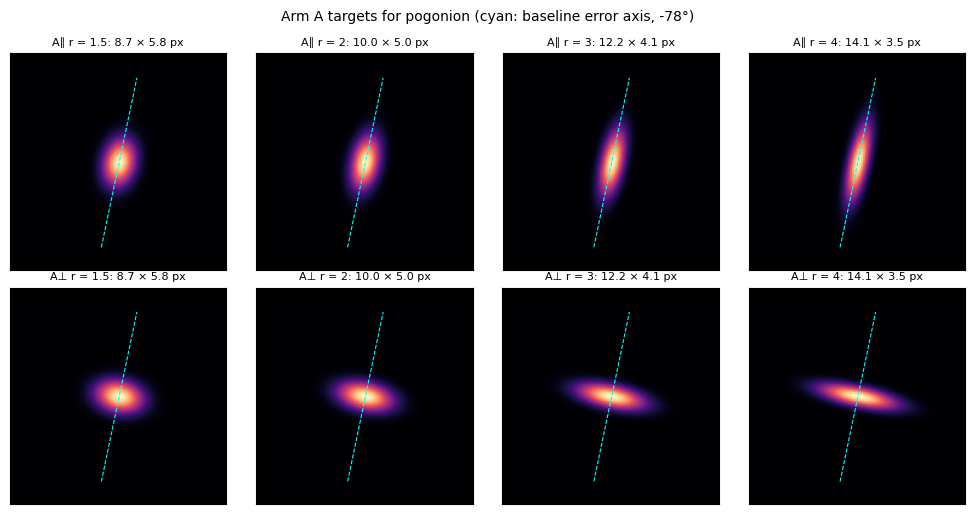

In [6]:
def arm_covariances(arm, width_mult, sigma0_px, k=K, ratio=1.0):
    """Per-landmark target covariance in the un-augmented canvas frame, px^2, shape (k, 2, 2).
    R: round, (w sigma0)^2 I.  Apar / Aperp: equal-area oval R(phi) diag(sigma0^2 r, sigma0^2 / r) R(phi)^T with phi = the
    landmark's baseline axis angle (Apar) or that angle + 90 degrees (Aperp); width_mult is not used (sigma_m = sigma0)."""
    if arm == "R":
        s = width_mult * sigma0_px
        return np.tile(np.eye(2) * s * s, (k, 1, 1))
    if arm in ("Apar", "Aperp"):
        phi = np.radians(np.asarray(AXIS_ANGLE_DEG[:k], float) + (0.0 if arm == "Apar" else 90.0))
        c, s = np.cos(phi), np.sin(phi)
        rot = np.stack([np.stack([c, -s], -1), np.stack([s, c], -1)], -2)          # (k, 2, 2), columns = long, short axis
        d = np.zeros((k, 2, 2)); d[:, 0, 0] = sigma0_px ** 2 * ratio; d[:, 1, 1] = sigma0_px ** 2 / ratio
        return rot @ d @ rot.transpose(0, 2, 1)
    raise NotImplementedError(f"arm {arm} is not defined in this notebook")

_YY = {}
def make_targets(pts, cov, H=None, W=None):
    """pts (B,K,2) canvas px [x,y]; cov (B,K,2,2). Returns (B,K,H,W) float32 Gaussians with peak 1."""
    H, W = H or H_C, W or W_C
    key = (H, W, str(pts.device))
    if key not in _YY:
        _YY[key] = (torch.arange(W, device=pts.device, dtype=torch.float32).view(1, 1, 1, W),
                    torch.arange(H, device=pts.device, dtype=torch.float32).view(1, 1, H, 1))
    xs, ys = _YY[key]
    inv = torch.linalg.inv(cov.float())
    dx = xs - pts[..., 0, None, None]
    dy = ys - pts[..., 1, None, None]
    q = inv[..., 0, 0, None, None] * dx * dx + 2 * inv[..., 0, 1, None, None] * dx * dy + inv[..., 1, 1, None, None] * dy * dy
    return torch.exp(-0.5 * q)

def in_canvas(pts, H=None, W=None):
    """(B,K) bool: landmark lies inside the canvas (after augmentation)."""
    H, W = H or H_C, W or W_C
    return (pts[..., 0] >= 0) & (pts[..., 0] <= W - 1) & (pts[..., 1] >= 0) & (pts[..., 1] <= H - 1)

def mass_normalised_mse(pred, target, cov, valid=None):
    """Per-channel SSE divided by the analytic target mass 2*pi*sqrt(det S), averaged over valid channels.
    The analytic mass does not shrink when a target is cut by the canvas border, and landmarks pushed off the
    canvas by augmentation (valid=False) are left out of that step's loss instead of dividing by a near-zero mass."""
    mass = 2 * math.pi * torch.sqrt(torch.linalg.det(cov.float()))
    se = ((pred.float() - target) ** 2).sum(dim=(2, 3))
    per = se / mass
    if valid is None:
        return per.mean()
    valid = valid.to(per.dtype)
    return (per * valid).sum() / valid.sum().clamp_min(1)

# checks: equal area (mass 2*pi*sigma0^2), long-axis direction and second moments of the rendered target, for every oval
p = torch.tensor([[[W_C / 2 + 0.3, H_C / 2 - 0.2]] * K], dtype=torch.float32)
_yy, _xx = np.mgrid[0:H_C, 0:W_C]
for sub in ("Apar", "Aperp"):
    for rl, r in RATIOS.items():
        cv = arm_covariances(sub, 1.0, SIGMA0_PX, ratio=r)
        assert np.allclose(np.sqrt(np.linalg.det(cv)), SIGMA0_PX ** 2), "oval area differs from the round baseline"
        ev, V = np.linalg.eigh(cv)
        ang = (np.degrees(np.arctan2(V[:, 1, 1], V[:, 0, 1])) + 90) % 180 - 90
        want = (np.asarray(AXIS_ANGLE_DEG) + (0 if sub == "Apar" else 90) + 90) % 180 - 90
        assert np.allclose(((ang - want) + 90) % 180 - 90, 0, atol=1e-6), "long axis is not at the intended angle"
        t = make_targets(p, torch.tensor(cv[None]))[0].numpy()
        for lm in (0, 6):                       # rendered second moments reproduce the covariance (sella, pogonion)
            w_ = t[lm] / t[lm].sum()
            mx, my = (w_ * _xx).sum(), (w_ * _yy).sum()
            emp = np.array([[(w_ * (_xx - mx) ** 2).sum(), (w_ * (_xx - mx) * (_yy - my)).sum()],
                            [(w_ * (_xx - mx) * (_yy - my)).sum(), (w_ * (_yy - my) ** 2).sum()]])
            assert np.allclose(emp, cv[lm], atol=0.05 * SIGMA0_PX ** 2 * r), (sub, rl, lm, emp, cv[lm])
            assert abs(t[lm].sum() / (2 * math.pi * SIGMA0_PX ** 2) - 1) < 0.02

LM_SHOW = 6                                    # pogonion: strongly anisotropic baseline errors
fig_t, axs = plt.subplots(2, 4, figsize=(10, 5.2))
p = torch.tensor([[[W_C / 2, H_C / 2]] * K], dtype=torch.float32)
half = min(int(4 * 2.0 * SIGMA0_PX) + 2, H_C // 2, W_C // 2)
for row, sub in enumerate(("Apar", "Aperp")):
    for ax, (rl, r) in zip(axs[row], RATIOS.items()):
        t = make_targets(p, torch.tensor(arm_covariances(sub, 1.0, SIGMA0_PX, ratio=r)[None]))[0, LM_SHOW].numpy()
        ax.imshow(t[H_C // 2 - half:H_C // 2 + half, W_C // 2 - half:W_C // 2 + half], cmap="magma", vmin=0, vmax=1)
        th = math.radians(AXIS_ANGLE_DEG[LM_SHOW])
        ax.plot([half - 0.8 * half * math.cos(th), half + 0.8 * half * math.cos(th)],
                [half - 0.8 * half * math.sin(th), half + 0.8 * half * math.sin(th)], color="cyan", lw=0.8, ls="--")
        ax.set_title(f"{'A∥' if sub == 'Apar' else 'A⊥'} r = {r:g}: {SIGMA0_PX * math.sqrt(r):.1f} × {SIGMA0_PX / math.sqrt(r):.1f} px",
                     fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
fig_t.suptitle(f"Arm A targets for {LANDMARKS[LM_SHOW]} (cyan: baseline error axis, {AXIS_ANGLE_DEG[LM_SHOW]:.0f}°)", fontsize=10)
fig_t.tight_layout()
fig_t.savefig(Path(RUN_ROOT) / "arm_A_targets.png", dpi=150)

## 4. Augmented training set

Per-sample randomness comes from `default_rng([seed, epoch, index])`, so two arms with the same seed see exactly the same images,
augmentations and batch order; only the target differs. There is no horizontal flip: all cephalograms face the same way, and a
flip would also mirror the error geometry.

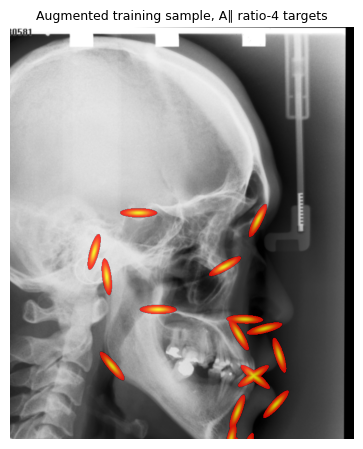

In [7]:
AUG = PROTOCOL["augmentation"]

class TrainSet(torch.utils.data.Dataset):
    def __init__(self, ids, seed, augment=True):
        self.ids, self.seed, self.augment, self.epoch = list(ids), int(seed), augment, 0

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, j):
        d = DATA[self.ids[j]]
        img, pts = d["img"], d["gt_canvas"]
        rot = np.eye(2)
        x = img.astype(np.float32) / 255.0
        if self.augment:
            rng = np.random.default_rng([self.seed, self.epoch, j])
            th = math.radians(rng.uniform(-AUG["rot_deg"], AUG["rot_deg"]))
            sc = math.exp(rng.uniform(math.log(AUG["scale"][0]), math.log(AUG["scale"][1])))
            sh = rng.uniform(-AUG["shift_frac"], AUG["shift_frac"], 2) * np.array([W_C, H_C])
            rot = np.array([[math.cos(th), -math.sin(th)], [math.sin(th), math.cos(th)]])
            A = sc * rot
            c = np.array([(W_C - 1) / 2, (H_C - 1) / 2])
            b = c + sh - A @ c
            M = np.hstack([A, b[:, None]])
            x = cv2.warpAffine(x, M, (W_C, H_C), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
            pts = pts @ A.T + b
            g = math.exp(rng.uniform(math.log(AUG["gamma"][0]), math.log(AUG["gamma"][1])))
            x = np.clip(x, 0, 1) ** g
            x = x * (1 + rng.uniform(-AUG["contrast"], AUG["contrast"])) + rng.uniform(-AUG["brightness"], AUG["brightness"])
        x = (x - x.mean()) / (x.std() + 1e-6)
        return (torch.from_numpy(x[None].astype(np.float32)), torch.from_numpy(pts.astype(np.float32)),
                torch.from_numpy(rot.astype(np.float32)))

def epoch_order(seed, epoch, n):
    return np.random.default_rng([seed, epoch, 10 ** 6]).permutation(n).tolist()

def plain_batch(ids):
    xs = []
    for i in ids:
        x = DATA[i]["img"].astype(np.float32) / 255.0
        xs.append((x - x.mean()) / (x.std() + 1e-6))
    return torch.from_numpy(np.stack(xs)[:, None])

# visual check: one augmented sample with its A∥ ratio-4 targets
_ds = TrainSet(TRAIN_IDS, seed=1)
_x, _p, _r = _ds[0]
_cov = torch.tensor(arm_covariances("Apar", 1.0, SIGMA0_PX, ratio=4.0)[None]).float()
_t = make_targets(_p[None], _r[None, None] @ _cov @ _r[None, None].transpose(-1, -2))[0].amax(0)
fig_a, ax = plt.subplots(figsize=(4, 4.6))
ax.imshow(_x[0], cmap="gray")
ax.imshow(np.ma.masked_less(_t.numpy(), 0.05), cmap="autumn", alpha=0.8)
ax.set_title("Augmented training sample, A∥ ratio-4 targets", fontsize=9)
ax.axis("off")
fig_a.tight_layout()
fig_a.savefig(Path(RUN_ROOT) / "arm_A_augmented_sample.png", dpi=150)

## 5. Network: UNet-32, 4 levels (Medium tier)

The proposal's tier table gives 7.8 M parameters and 123 GMACs at 768² for 12 heatmaps without batch norm. With 19 heatmaps,
batch norm and the 768 × 640 ISBI canvas, the counts are 7,766,003 parameters and ≈ 90.5 GMACs (convolution MACs, 1/4 of UNet-64). The parameter
count is asserted. Same architecture as the High tier (4 levels, same blocks), only the base width differs, so capacity is not
confounded with architecture.

In [8]:
class DoubleConv(nn.Sequential):
    def __init__(self, ci, co):
        super().__init__(nn.Conv2d(ci, co, 3, padding=1, bias=True), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
                         nn.Conv2d(co, co, 3, padding=1, bias=True), nn.BatchNorm2d(co), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=K, base=64, levels=4):
        super().__init__()
        ch = [base * 2 ** i for i in range(levels + 1)]
        self.down = nn.ModuleList()
        c = in_ch
        for i in range(levels):
            self.down.append(DoubleConv(c, ch[i])); c = ch[i]
        self.bottom = DoubleConv(ch[levels - 1], ch[levels])
        self.up = nn.ModuleList([nn.ConvTranspose2d(ch[i + 1], ch[i], 2, stride=2) for i in reversed(range(levels))])
        self.dec = nn.ModuleList([DoubleConv(2 * ch[i], ch[i]) for i in reversed(range(levels))])
        self.head = nn.Conv2d(ch[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for blk in self.down:
            x = blk(x); skips.append(x); x = F.max_pool2d(x, 2)
        x = self.bottom(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), s], 1))
        return self.head(x)

N_PARAMS = sum(p.numel() for p in UNet(base=UNET_BASE).parameters())
if not SMOKE_TEST:
    assert N_PARAMS == 7_766_003, N_PARAMS
assert H_C % 16 == 0 and W_C % 16 == 0
print("UNet base", UNET_BASE, "| parameters", f"{N_PARAMS / 1e6:.3f} M")

UNet base 32 | parameters 7.766 M


## 6. Decoders

All four decoders run on the same checkpoints at no training cost (plan §4.2, convention 3). The window radius is the same in every
arm, so the decoder does not change with the target. `gaussfit` also returns the covariance of the fitted heatmap peak, which records
whether the predicted heatmap itself follows the target shape.

* `argmax`: integer peak (gives the rounding cost).
* `quadratic`: second-order Taylor step on the log heatmap in the 3 × 3 neighbourhood of the peak (PROVISIONAL primary).
* `softargmax_local`: centroid of the positive heatmap inside the window.
* `gaussfit`: weighted least squares of a full-covariance 2-D Gaussian to the log heatmap where it exceeds 10% of the peak.

In [9]:
def heatmap_windows(hm, r=None):
    """hm (B,K,H,W) float tensor -> integer peaks (B,K,2) [x,y] and windows (B,K,2r+1,2r+1) as numpy (NaN outside image)."""
    r = r or R_WIN
    B, Kk, H, W = hm.shape
    flat = hm.reshape(B, Kk, -1).argmax(-1)
    iy, ix = (flat // W), (flat % W)
    pad = F.pad(hm, (r, r, r, r), value=float("nan"))
    ar = torch.arange(2 * r + 1, device=hm.device)
    idx_y = (iy[..., None] + ar)[..., None].expand(B, Kk, 2 * r + 1, W + 2 * r)
    rows = torch.gather(pad, 2, idx_y)
    idx_x = (ix[..., None] + ar)[:, :, None, :].expand(B, Kk, 2 * r + 1, 2 * r + 1)
    win = torch.gather(rows, 3, idx_x)
    peaks = torch.stack([ix, iy], -1)
    return peaks.cpu().numpy().astype(np.float64), win.float().cpu().numpy().astype(np.float64)

_GRID = {}
def decode_window(w):
    """w: (2r+1,2r+1) window centred on the integer peak. Returns offsets (dx,dy) per decoder and the fitted covariance."""
    r = w.shape[0] // 2
    out = {"argmax": (0.0, 0.0)}
    peak = w[r, r]
    # quadratic (Taylor step on the log heatmap)
    off = (0.0, 0.0)
    nb = w[r - 1:r + 2, r - 1:r + 2]
    if peak > 0 and np.all(np.isfinite(nb)):
        L = np.log(np.clip(nb, 1e-6 * peak, None))
        gx, gy = (L[1, 2] - L[1, 0]) / 2, (L[2, 1] - L[0, 1]) / 2
        hxx, hyy = L[1, 2] - 2 * L[1, 1] + L[1, 0], L[2, 1] - 2 * L[1, 1] + L[0, 1]
        hxy = (L[2, 2] - L[2, 0] - L[0, 2] + L[0, 0]) / 4
        Hm = np.array([[hxx, hxy], [hxy, hyy]])
        if hxx < 0 and np.linalg.det(Hm) > 0:
            o = -np.linalg.solve(Hm, [gx, gy])
            off = tuple(float(v) for v in np.clip(o, -1, 1))
    out["quadratic"] = off
    # local soft-argmax
    if r not in _GRID:
        g = np.arange(-r, r + 1, dtype=np.float64)
        _GRID[r] = np.meshgrid(g, g)
    gx_, gy_ = _GRID[r]
    pw = np.where(np.isfinite(w), np.clip(w, 0, None), 0.0)
    out["softargmax_local"] = ((pw * gx_).sum() / pw.sum(), (pw * gy_).sum() / pw.sum()) if pw.sum() > 0 else (0.0, 0.0)
    # Gaussian fit (falls back to the quadratic step)
    out["gaussfit"], out["gauss_cov"] = off, (np.nan, np.nan, np.nan)
    m = (np.isfinite(w) & (w > 0.1 * peak)) if peak > 0 else np.zeros(w.shape, bool)
    if m.sum() >= 6:
        X, Y, V = gx_[m], gy_[m], w[m]
        Amat = np.stack([np.ones_like(X), X, Y, X * X, X * Y, Y * Y], 1)
        sw = np.sqrt(V)
        coef, *_ = np.linalg.lstsq(Amat * sw[:, None], np.log(V) * sw, rcond=None)
        A2 = np.array([[coef[3], coef[4] / 2], [coef[4] / 2, coef[5]]])
        if np.all(np.linalg.eigvalsh(A2) < 0):
            S = -0.5 * np.linalg.inv(A2)
            mu = S @ coef[1:3]
            if np.all(np.abs(mu) <= r):
                out["gaussfit"], out["gauss_cov"] = (float(mu[0]), float(mu[1])), (S[0, 0], S[0, 1], S[1, 1])
    return out

# unit check on noiseless Gaussians at sub-pixel positions
_errs = {d: [] for d in PROTOCOL["decoders"]}
for (x0, y0) in [(40.3, 31.7), (52.6, 20.2), (33.5, 44.5)]:
    for sg in (SIGMA0_R_PX * 2 ** -0.5, SIGMA0_R_PX):   # same widths as the arm R check (the grid unit, not this tier's sigma0)
        cov = torch.tensor(np.eye(2)[None, None] * sg ** 2)
        hm = make_targets(torch.tensor([[[x0, y0]]], dtype=torch.float32), cov, 80, 96)
        pk, win = heatmap_windows(hm)
        dec = decode_window(win[0, 0])
        for d in PROTOCOL["decoders"]:
            _errs[d].append(math.hypot(pk[0, 0, 0] + dec[d][0] - x0, pk[0, 0, 1] + dec[d][1] - y0))
_maxerr = {d: round(max(v), 4) for d, v in _errs.items()}
assert _maxerr["quadratic"] < 0.02 and _maxerr["gaussfit"] < 0.02 and _maxerr["softargmax_local"] < 0.1, _maxerr
print("decoder max error on noiseless Gaussians (px):", _maxerr)

# Information only (no assert): softargmax_local is a centroid inside the fixed window, so it is pulled towards the integer peak
# when the target is wide relative to the window. At 7.07 px with the 15 px window the bias is ~0.1 px, and along the long axis
# of the widest ovals (r = 4: 14.1 px) it is ~0.4 px. quadratic (primary) and gaussfit are unaffected. This only matters for the
# softargmax sensitivity variant in section 10, where it shrinks long-axis spread and so biases alpha towards 0.
_wide = {}
for sg in (SIGMA0_PX, SIGMA0_PX * 2.0):
    _e = []
    for (x0, y0) in [(40.3, 31.7), (52.6, 20.2), (33.5, 44.5)]:
        hm = make_targets(torch.tensor([[[x0, y0]]], dtype=torch.float32), torch.tensor(np.eye(2)[None, None] * sg ** 2), 80, 96)
        pk, win = heatmap_windows(hm)
        dec = decode_window(win[0, 0])
        _e.append({d: math.hypot(pk[0, 0, 0] + dec[d][0] - x0, pk[0, 0, 1] + dec[d][1] - y0) for d in PROTOCOL["decoders"]})
    _wide[f"{sg:.2f}px"] = {d: round(max(e[d] for e in _e), 3) for d in PROTOCOL["decoders"]}
print("decoder max error at this tier's widths (sigma0, 2 x sigma0; information only):", _wide)

decoder max error on noiseless Gaussians (px): {'argmax': 0.7071, 'quadratic': 0.0, 'softargmax_local': 0.0144, 'gaussfit': 0.0}
decoder max error at this tier's widths (sigma0, 2 x sigma0; information only): {'7.07px': {'argmax': 0.707, 'quadratic': 0.0, 'softargmax_local': 0.115, 'gaussfit': 0.0}, '14.14px': {'argmax': 0.707, 'quadratic': 0.0, 'softargmax_local': 0.467, 'gaussfit': 0.0}}


## 7. Prediction and per-landmark statistics

In [10]:
@torch.no_grad()
def predict(model, ids, batch=4):
    model.eval()
    recs = []
    for k0 in range(0, len(ids), batch):
        bid = ids[k0:k0 + batch]
        x = plain_batch(bid).to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            hm = model(x)
        peaks, wins = heatmap_windows(hm.float())
        for b, i in enumerate(bid):
            d = DATA[i]
            for k in range(K):
                dec = decode_window(wins[b, k])
                for name in PROTOCOL["decoders"]:
                    xc, yc = peaks[b, k, 0] + dec[name][0], peaks[b, k, 1] + dec[name][1]
                    xo, yo = canvas_to_orig(xc, d["s"]), canvas_to_orig(yc, d["s"])
                    dx, dy = (xo - d["gt_orig"][k, 0]) * MM, (yo - d["gt_orig"][k, 1]) * MM
                    recs.append((i, d["subset"], k + 1, name, xo, yo, dx, dy, math.hypot(dx, dy),
                                 wins[b, k, R_WIN, R_WIN], *dec["gauss_cov"]))
    return pd.DataFrame(recs, columns=["image_id", "subset", "landmark", "decoder", "x_pred", "y_pred",
                                       "dx_mm", "dy_mm", "r_mm", "peak", "fit_sxx", "fit_sxy", "fit_syy"])

def _madsd(v):
    return 1.4826 * float(np.median(np.abs(v - np.median(v))))

def spread_stats(dx, dy, fail_mm=None):
    """Spread after the gross-failure cut. Major-axis angle in degrees from +x towards +y (image frame)."""
    fail_mm = PROTOCOL["gross_failure_mm"] if fail_mm is None else fail_mm
    dx, dy = np.asarray(dx, float), np.asarray(dy, float)
    r = np.hypot(dx, dy)
    keep = r <= fail_mm
    out = {"n": len(r), "n_kept": int(keep.sum()), "fail_rate": float(1 - keep.mean()), "mre_mm": float(r.mean())}
    for t in PROTOCOL["sdr_mm"]:
        out[f"sdr_{t:g}mm"] = float((r <= t).mean())
    if keep.sum() >= 5:
        ex, ey = dx[keep], dy[keep]
        C = np.cov(np.stack([ex, ey]))
        ev, V = np.linalg.eigh(C)
        ang = (math.degrees(math.atan2(V[1, 1], V[0, 1])) + 90) % 180 - 90
        out.update({"bias_x_mm": ex.mean(), "bias_y_mm": ey.mean(), "sd_x": math.sqrt(C[0, 0]), "sd_y": math.sqrt(C[1, 1]),
                    "cov_xy": C[0, 1], "sd_iso": math.sqrt(np.trace(C) / 2), "sd_major": math.sqrt(max(ev[1], 0)),
                    "sd_minor": math.sqrt(max(ev[0], 0)), "angle_major_deg": ang,
                    "sd_ratio": math.sqrt(ev[1] / ev[0]) if ev[0] > 0 else np.nan,
                    "madsd_x": _madsd(ex), "madsd_y": _madsd(ey)})
    return out

def summarise(pred):
    rows = []
    for (dec, lm), g in pred.groupby(["decoder", "landmark"]):
        rows.append({"decoder": dec, "landmark": lm, **spread_stats(g.dx_mm, g.dy_mm)})
    for dec, g in pred.groupby("decoder"):   # landmark 0 = all landmarks pooled (accuracy only)
        st = spread_stats(g.dx_mm, g.dy_mm)
        rows.append({"decoder": dec, "landmark": 0, **{k: v for k, v in st.items()
                                                      if k in ("n", "n_kept", "fail_rate", "mre_mm") or k.startswith("sdr")}})
    return pd.DataFrame(rows)

## 8. Training one run

**Checkpoint names carry their hash.** Every saved model is written as `<stem>_<sha8>.pt`, where `sha8` is the last 8 hex
characters of the file's SHA-256 (for example `final_3fa9c01e.pt`, `snap_e50pct_…pt`, `snap_e75pct_…pt`). The file is written to a
temporary name, hashed, then renamed, so the suffix always matches the content. The full SHA-256 goes into `config.json`
(`checkpoints`), the `DONE` marker (protocol hash, final file name, full SHA-256), and the `checkpoint_sha8` column of
`predictions_test.csv.gz` and `summary_final.csv`. Each prediction row therefore names the exact model that produced it. The suffix is
re-checked whenever a checkpoint is loaded. `last.pt` is only the overwritten resume file and is deleted when the run finishes.

In [11]:
CONV_IDS = sorted(np.random.default_rng(0).choice(TRAIN_IDS, 20, replace=False).tolist())

def lr_at(it, iters_per_epoch, total_iters):
    o = PROTOCOL["optimiser"]
    warm = o["warmup_epochs"] * iters_per_epoch
    if it < warm:
        return o["lr"] * (it + 1) / warm
    prog = (it - warm) / max(1, total_iters - warm)
    return 1e-6 + 0.5 * (o["lr"] - 1e-6) * (1 + math.cos(math.pi * prog))

def file_sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def save_checkpoint(state, out_dir, stem):
    """Save to <stem>_<sha8>.pt, where sha8 = last 8 hex characters of the file's SHA-256.
    Any older <stem>_<8 hex>.pt in the same run folder (e.g. from an interrupted save) is removed first."""
    out_dir = Path(out_dir)
    for old in out_dir.glob(f"{stem}_*.pt"):
        if re.fullmatch(rf"{re.escape(stem)}_[0-9a-f]{{8}}\.pt", old.name):
            old.unlink()
    tmp = out_dir / f"{stem}.pt.tmp"
    torch.save(state, tmp)
    sha = file_sha256(tmp)
    path = out_dir / f"{stem}_{sha[-8:]}.pt"
    os.replace(tmp, path)
    return path, sha

def find_checkpoint(out_dir, stem, verify=True):
    """Return (path, sha256) of the single <stem>_<sha8>.pt in out_dir, or (None, None). Verifies the suffix."""
    hits = [p for p in Path(out_dir).glob(f"{stem}_*.pt")
            if re.fullmatch(rf"{re.escape(stem)}_[0-9a-f]{{8}}\.pt", p.name)]
    if not hits:
        return None, None
    assert len(hits) == 1, f"more than one {stem} checkpoint in {out_dir}: {[p.name for p in hits]}"
    sha = file_sha256(hits[0]) if verify else None
    if verify:
        assert sha[-8:] == hits[0].stem.rsplit("_", 1)[1], f"{hits[0].name}: content does not match its SHA-256 suffix"
    return hits[0], sha

def _grad_scaler():
    enabled = AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

try:
    from tqdm.auto import tqdm as _tqdm
except ImportError:
    _tqdm = None

class _PrintProgress:
    """Fallback when tqdm is missing: one line at every convergence check (every 25 epochs)."""
    def __init__(self, desc, total, initial):
        self.desc, self.total, self.n, self.t0, self.post = desc, total, initial, time.time(), {}
        self.n0 = initial
    def set_postfix(self, refresh=False, **kw):
        self.post = kw
    def update(self, k=1):
        self.n += k
        if self.n % 25 == 0 or self.n == self.total:
            eta = (time.time() - self.t0) / max(self.n - self.n0, 1) * (self.total - self.n) / 3600
            print(f"{self.desc}: epoch {self.n}/{self.total}, " + ", ".join(f"{k} {v}" for k, v in self.post.items())
                  + f", ETA {eta:.2f} h", flush=True)
    def close(self):
        pass

def epoch_bar(run_id, start_ep):
    desc = run_id.replace(f"C0_ISBI2015_{TIER}_{ARM}_", "")
    if not PROGRESS_BAR:
        return None
    if _tqdm is None:
        return _PrintProgress(desc, EPOCHS, start_ep)
    return _tqdm(total=EPOCHS, initial=start_ep, desc=desc, unit="ep", mininterval=1.0, dynamic_ncols=True, leave=True)

def train_run(run):
    out = Path(RUN_ROOT) / run["run_id"]
    if (out / "DONE").exists():
        print("skip (done):", run["run_id"]); return
    out.mkdir(parents=True, exist_ok=True)
    seed = int(run["seed"])
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    model = UNet(base=UNET_BASE).to(DEVICE)
    o = PROTOCOL["optimiser"]
    opt = torch.optim.AdamW(model.parameters(), lr=o["lr"], weight_decay=o["weight_decay"])
    scaler = _grad_scaler()
    ds = TrainSet(TRAIN_IDS, seed)
    ipe = len(TRAIN_IDS) // BATCH_SIZE
    total = EPOCHS * ipe
    base_cov = torch.tensor(arm_covariances(run["arm"], run["width_mult"], SIGMA0_PX, ratio=run.get("ratio", 1.0)),
                            dtype=torch.float32, device=DEVICE)
    start_ep, log = 0, []
    if (out / "last.pt").exists():
        ck = torch.load(out / "last.pt", map_location=DEVICE, weights_only=False)
        assert ck["protocol_hash"] == PROTOCOL_HASH, "protocol changed since this run started"
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        start_ep, log = ck["epoch"] + 1, ck["log"]
        print("resume", run["run_id"], "from epoch", start_ep)
    cfg = {"run": run, "protocol": PROTOCOL, "protocol_hash": PROTOCOL_HASH, "arm_spec": ARM_SPEC, "arm_hash": ARM_HASH,
           "env": ENV_INFO, "sigma0_px": SIGMA0_PX,
           "unet_base": UNET_BASE, "n_params": N_PARAMS, "conv_ids": CONV_IDS,
           "started": dt.datetime.now().isoformat(timespec="seconds")}
    (out / "config.json").write_text(json.dumps(cfg, indent=1, default=str))
    snaps = {max(int(EPOCHS * 0.5) - 1, 0): "e50pct", max(int(EPOCHS * 0.75) - 1, 0): "e75pct"}
    t_run = time.time()
    bar = epoch_bar(run["run_id"], start_ep)
    for ep in range(start_ep, EPOCHS):
        model.train(); ds.epoch = ep
        dl = torch.utils.data.DataLoader(ds, batch_size=BATCH_SIZE, sampler=epoch_order(seed, ep, len(ds)),
                                         num_workers=NUM_WORKERS, drop_last=True, pin_memory=DEVICE.type == "cuda")
        t0, losses, n_off = time.time(), [], 0
        for it_in, (x, p, rot) in enumerate(dl):
            it = ep * ipe + it_in
            for gp in opt.param_groups:
                gp["lr"] = lr_at(it, ipe, total)
            x, p, rot = x.to(DEVICE, non_blocking=True), p.to(DEVICE), rot.to(DEVICE)
            cov = rot[:, None] @ base_cov[None] @ rot[:, None].transpose(-1, -2)
            tgt = make_targets(p, cov)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
                pred = model(x)
            valid = in_canvas(p)
            n_off += int((~valid).sum())
            loss = mass_normalised_mse(pred, tgt, cov, valid)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            losses.append(loss.item())
        rec = {"epoch": ep + 1, "loss": float(np.mean(losses)), "lr": float(opt.param_groups[0]["lr"]),
               "sec": time.time() - t0, "n_landmarks_off_canvas": n_off}
        if (ep + 1) % 25 == 0 or ep + 1 == EPOCHS:
            pr = predict(model, CONV_IDS)
            rec["conv_mre_mm"] = float(pr[pr.decoder == PROTOCOL["primary_decoder"]].r_mm.mean())
        log.append(rec)
        if bar is not None:
            mre = next((r["conv_mre_mm"] for r in reversed(log) if "conv_mre_mm" in r), None)
            bar.set_postfix(loss=f"{rec['loss']:.4g}", train_mre_mm="-" if mre is None else f"{mre:.2f}",
                            s_per_ep=f"{rec['sec']:.1f}", refresh=False)
            bar.update(1)
        if ep in snaps:
            save_checkpoint({k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()},
                            out, f"snap_{snaps[ep]}")
        if (ep + 1) % 50 == 0 or ep + 1 == EPOCHS:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(), "epoch": ep,
                        "log": log, "protocol_hash": PROTOCOL_HASH}, out / "last.pt")
            pd.DataFrame(log).to_csv(out / "train_log.csv", index=False)
        if bar is None and ep == start_ep:
            print(f"{run['run_id']}: epoch {ep + 1} took {rec['sec']:.1f} s -> projected "
                  f"{rec['sec'] * (EPOCHS - ep) / 3600:.2f} h for the rest of the run")
    if bar is not None:
        bar.close()
    final_path, final_sha = save_checkpoint(model.state_dict(), out, "final")
    lg = pd.DataFrame(log); lg.to_csv(out / "train_log.csv", index=False)
    cm = lg.conv_mre_mm.dropna().values
    converged = bool(len(cm) >= 8 and abs(cm[-4:].mean() - cm[-8:-4].mean()) <= 0.02 * cm[-8:-4].mean())
    # evaluation: final checkpoint (the one used) and snapshots (convergence report only, never selected)
    preds, ckpts = [], {}
    stems = {"final": "final", **{t: f"snap_{t}" for t in sorted(set(snaps.values()))}}
    for tag, stem in stems.items():
        path, sha = find_checkpoint(out, stem)
        assert path is not None, f"{run['run_id']}: expected checkpoint {stem}_<sha8>.pt not found"
        ckpts[tag] = {"file": path.name, "sha256": sha}
        model.load_state_dict({k: v.float() if v.is_floating_point() else v
                               for k, v in torch.load(path, map_location=DEVICE).items()})
        pr = predict(model, TEST_IDS)
        pr.insert(0, "checkpoint_sha8", sha[-8:]); pr.insert(0, "checkpoint", tag); preds.append(pr)
    assert ckpts["final"]["sha256"] == final_sha
    pred = pd.concat(preds, ignore_index=True)
    assert set(pred.checkpoint) == set(stems), f"evaluated {set(pred.checkpoint)}, expected {set(stems)}"
    pred.insert(0, "run_id", run["run_id"])
    pred.to_csv(out / "predictions_test.csv.gz", index=False)
    summ = summarise(pred[pred.checkpoint == "final"])
    summ.insert(0, "checkpoint_sha8", final_sha[-8:]); summ.insert(0, "run_id", run["run_id"])
    summ.to_csv(out / "summary_final.csv", index=False)
    cfg.update({"finished": dt.datetime.now().isoformat(timespec="seconds"),
                "train_hours_this_session": (time.time() - t_run) / 3600,
                "sec_per_epoch_median": float(lg.sec.median()), "converged": converged, "checkpoints": ckpts})
    (out / "config.json").write_text(json.dumps(cfg, indent=1, default=str))
    (out / "last.pt").unlink(missing_ok=True)
    (out / "DONE").write_text(f"{PROTOCOL_HASH}\n{final_path.name}\n{final_sha}\n{ARM_HASH}\n")
    s0 = summ[(summ.decoder == PROTOCOL["primary_decoder"]) & (summ.landmark == 0)].iloc[0]
    print(f"done {run['run_id']} -> {final_path.name}: MRE {s0.mre_mm:.3f} mm, SDR 2 mm {s0.sdr_2mm:.3f}, "
          f"gross failures {s0.fail_rate:.3f}, converged {converged}, {lg.sec.median() * EPOCHS / 3600:.2f} h/run")

## 9. Execute the selected runs

In [12]:
todo = RUN_TABLE if RUN_IDS == "all" else RUN_TABLE[RUN_TABLE.run_id.isin(RUN_IDS)]
assert len(todo) > 0, "RUN_IDS matched no run"
for _, run in todo.iterrows():
    train_run(run.to_dict())

C0_ISBI2015_Medium_Apar_r2.00_s1:   0%|          | 0/800 [00:00<?, ?ep/s]

done C0_ISBI2015_Medium_Apar_r2.00_s1 -> final_ad75285c.pt: MRE 1.301 mm, SDR 2 mm 0.814, gross failures 0.032, converged False, 1.41 h/run


C0_ISBI2015_Medium_Aperp_r3.00_s2:   0%|          | 0/800 [00:00<?, ?ep/s]

done C0_ISBI2015_Medium_Aperp_r3.00_s2 -> final_774f82d8.pt: MRE 1.346 mm, SDR 2 mm 0.809, gross failures 0.035, converged False, 1.41 h/run


C0_ISBI2015_Medium_Apar_r4.00_s3:   0%|          | 0/800 [00:00<?, ?ep/s]

done C0_ISBI2015_Medium_Apar_r4.00_s3 -> final_1b5ff685.pt: MRE 1.305 mm, SDR 2 mm 0.807, gross failures 0.036, converged False, 1.41 h/run


C0_ISBI2015_Medium_Aperp_r1.50_s3:   0%|          | 0/800 [00:00<?, ?ep/s]

done C0_ISBI2015_Medium_Aperp_r1.50_s3 -> final_859ae962.pt: MRE 1.320 mm, SDR 2 mm 0.809, gross failures 0.036, converged False, 1.40 h/run


## 10. Arm-level analysis (runs once all 24 oval runs and the three paired B0 runs are available)

Plan §5. Everything is a change relative to the paired round baseline B0 (arm R at σ₀ = 7.07 px, `w1.41`, same seed), never an
absolute direction.

* **Per run and landmark:** errors after the 4 mm gross-failure cut are projected onto the landmark's two baseline axes
  (u = baseline major axis, v = u + 90°). For A∥ the target's long axis is u, for A⊥ it is v. The spread is the SD along each axis;
  the sensitivity analysis uses 1.4826 × MAD.
* **Response:** Δ log SD along each target axis = log SD(oval run) − log SD(paired B0 run), same axis direction, same decoder.
* **Q1 (primary):** per landmark, OLS of Δ log SD on log(σ_d / σ₀) over its A∥ and A⊥ observations (two per run: long axis
  σ_d = σ₀√r, short axis σ_d = σ₀/√r), with an intercept. The slope is α_i. Pooled α = mean of α_i, one-sided t-test across
  landmarks; "transfer established" if the one-sided 95 % lower bound exceeds 0.1 (P0a).
* **P0b:** the same with A⊥ observations only, on landmarks with a defined axis and baseline SD ratio ≥ 1.3 (target and image disagree).
* **Usable cells** (same rule as arm R): an observation enters only if both the oval cell and its paired B0 cell have ≤ 5 % gross
  failures. Gross-failure rates per arm and ratio are reported separately (`fail_by_ratio.csv`), because an oval whose short axis is
  below the detectability floor is a result of its own.
* **Sensitivity:** all cells (no usable filter), MAD instead of SD, and the alternative decoders (`softargmax_local`, `gaussfit`, `argmax`).
* **Separability (ratio 2):** each oval axis's SD against the arm R run of the same width (`w2.00` long, `w1.00` short), same
  seed and axis direction. Ratio 4 is not available at this tier (its 14.1 px long axis would need `w2.83` round runs, which
  were not trained). Needs those arm R runs in `RUN_ROOT`; skipped otherwise.
* **Heatmap shape:** the `gaussfit` decoder also fits the predicted heatmap's covariance; its long-axis angle is compared with the
  target's, which shows whether the network reproduces the oval at all.

The paired B0 runs come from arm R in the same `RUN_ROOT`. On a pod that only trained arm A, copy the folders
`C0_ISBI2015_Medium_R_w1.41_s{1,2,3}` (and for separability `w1.00`, `w2.00`)
into `RUN_ROOT` (DONE, config.json, summary_final.csv, predictions_test.csv.gz; model files are optional), or run this section
locally where the arm R runs are.

In [13]:
def load_final_preds(rid, need_arm_hash):
    d = Path(RUN_ROOT) / rid
    if not (d / "DONE").exists():
        return None
    done = (d / "DONE").read_text().split()
    assert done[0] == PROTOCOL_HASH, f"{rid} ran under a different protocol"
    assert len(done) >= 3 and done[2].endswith(done[1][-11:-3]), f"{rid}: DONE marker is malformed"
    ck = d / done[1]
    if ck.exists():                     # verify the checkpoint when it is there; the analysis itself needs only the predictions
        assert file_sha256(ck) == done[2], f"{rid}: {ck.name} does not match the SHA-256 in DONE"
        CKPT_STATUS[rid] = "verified"
    else:
        CKPT_STATUS[rid] = "not present (DONE only)"
    if need_arm_hash:
        assert len(done) >= 4 and done[3] == ARM_HASH, f"{rid} was trained with a different oval specification (arm hash)"
    p = pd.read_csv(d / "predictions_test.csv.gz")
    return p[p.checkpoint == "final"]

CKPT_STATUS = {}
A_PRED = {rid: load_final_preds(rid, True) for rid in RUN_TABLE.run_id}
B0_PRED = {s: load_final_preds(B0_RUN[s], False) for s in PAIRED_SEEDS}
R_PRED = {(wl, s): load_final_preds(R_RUN(wl, s), False) for wl in ("1.00", "2.00") for s in PAIRED_SEEDS}
n_done = sum(v is not None for v in A_PRED.values())
print("oval runs done:", n_done, "of", len(RUN_TABLE), "| paired B0 runs found:", sum(v is not None for v in B0_PRED.values()),
      "of 3 | arm R comparison runs found:", sum(v is not None for v in R_PRED.values()), "of 12")

oval runs done: 22 of 24 | paired B0 runs found: 0 of 3 | arm R comparison runs found: 0 of 12


In [14]:
AGG = Path(RUN_ROOT) / "arm_A_summary"
AGG.mkdir(exist_ok=True)
MAX_FAIL_CELL = 0.05      # a cell enters the alpha fit only if <= 5 % of its errors (and of its paired B0 cell's) exceed 4 mm
MIN_OBS = 8               # fewer usable axis observations than this -> no alpha_i for the landmark (max 48 per landmark)
P0B_MIN_SD_RATIO = 1.3    # plan P0b: landmarks where target and image disagree clearly
DECODERS = PROTOCOL["decoders"]
PD = PROTOCOL["primary_decoder"]
FAIL_MM = PROTOCOL["gross_failure_mm"]
_LOCK = AGG / ".analysis.lock"

def _acquire_lock(stale_s=3600):
    if _LOCK.exists() and time.time() - _LOCK.stat().st_mtime > stale_s:
        _LOCK.unlink(missing_ok=True)          # left behind by a crashed analysis
    try:
        os.close(os.open(_LOCK, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        return True
    except FileExistsError:
        print(f"another notebook is running the arm-level analysis now (or a stale lock is left at {_LOCK}); skipped here")
        return False

READY = n_done == len(RUN_TABLE) and all(v is not None for v in B0_PRED.values())
if not READY:
    print("arm-level analysis waits for:", [r for r, v in A_PRED.items() if v is None][:6],
          [B0_RUN[s] for s, v in B0_PRED.items() if v is None])
HAVE_LOCK = READY and _acquire_lock()

_th = np.radians(np.asarray(AXIS_ANGLE_DEG, float))
AX_U = np.stack([np.cos(_th), np.sin(_th)], 1)       # baseline major axis, image frame (x right, y down)
AX_V = np.stack([-np.sin(_th), np.cos(_th)], 1)      # u + 90 degrees

def _madsd_np(v):
    return 1.4826 * float(np.median(np.abs(v - np.median(v)))) if len(v) else np.nan

def axis_stats(pred):
    """Per decoder and landmark: failure rate, SD and MAD-SD along u and v after the gross-failure cut."""
    out = {}
    for (dec, lm), h in pred.groupby(["decoder", "landmark"]):
        keep = (h.r_mm <= FAIL_MM).values
        ex, ey = h.dx_mm.values[keep], h.dy_mm.values[keep]
        pu = ex * AX_U[lm - 1, 0] + ey * AX_U[lm - 1, 1]
        pv = ex * AX_V[lm - 1, 0] + ey * AX_V[lm - 1, 1]
        ok = keep.sum() >= 5
        out[(dec, lm)] = {"fail": float(1 - keep.mean()), "n_kept": int(keep.sum()),
                          "sd_u": float(np.std(pu, ddof=1)) if ok else np.nan, "sd_v": float(np.std(pv, ddof=1)) if ok else np.nan,
                          "mad_u": _madsd_np(pu) if ok else np.nan, "mad_v": _madsd_np(pv) if ok else np.nan}
    return out

def fit_alpha(obs, ycol):
    rows = []
    for lm in range(1, K + 1):
        g = obs[(obs.landmark == lm)]
        g = g[np.isfinite(g[ycol])]
        row = {"landmark": lm, "n_obs": len(g), "alpha": np.nan, "alpha_se": np.nan, "intercept": np.nan}
        if len(g) >= MIN_OBS and g.x.nunique() >= 3:
            (b1, b0), cv = np.polyfit(g.x, g[ycol], 1, cov=True)
            row.update({"alpha": b1, "alpha_se": math.sqrt(cv[0, 0]), "intercept": b0})
        rows.append(row)
    return pd.DataFrame(rows)

def pooled_alpha(a):
    a = np.asarray([v for v in a if np.isfinite(v)], float)
    n = len(a)
    if n < 3:
        return {"n_landmarks": n, "alpha": float(np.mean(a)) if n else None, "note": "fewer than 3 landmarks"}
    m, se = float(a.mean()), float(a.std(ddof=1) / math.sqrt(n))
    try:
        from scipy import stats as _st
        tq95, tq975 = _st.t.ppf(0.95, n - 1), _st.t.ppf(0.975, n - 1)
        p1 = float(_st.t.sf(m / se, n - 1)) if se > 0 else (0.0 if m > 0 else 1.0)
    except ImportError:                       # normal approximation if scipy is missing
        tq95, tq975 = 1.645, 1.96
        p1 = float(0.5 * math.erfc((m / se) / math.sqrt(2))) if se > 0 else (0.0 if m > 0 else 1.0)
    lo = m - tq95 * se
    verdict = ("transfer established (one-sided lower bound > 0.1)" if p1 < 0.05 and lo > 0.1 else
               "transfer detected but weak (alpha > 0, lower bound <= 0.1)" if p1 < 0.05 else
               "alpha < 0: sigma0 may be too narrow at many landmarks (plan: repeat aspect arms at 1.41 sigma0)"
               if m + tq975 * se < 0 else "no transfer detected")
    return {"n_landmarks": n, "alpha": round(m, 4), "se": round(se, 4), "t": round(m / se, 3) if se > 0 else None,
            "p_one_sided": round(p1, 5), "lower95_one_sided": round(lo, 4),
            "ci95": [round(m - tq975 * se, 4), round(m + tq975 * se, 4)], "verdict": verdict}

if HAVE_LOCK:
    try:
        B0S = {s: axis_stats(B0_PRED[s]) for s in PAIRED_SEEDS}
        rec = []
        for _, run in RUN_TABLE.iterrows():
            st = axis_stats(A_PRED[run.run_id])
            b0 = B0S[int(run.seed)]
            half = 0.5 * math.log(run.ratio)
            for (dec, lm), a in st.items():
                b = b0[(dec, lm)]
                major, minor = ("u", "v") if run.arm == "Apar" else ("v", "u")
                for axis, d, x in (("long", major, half), ("short", minor, -half)):
                    rec.append({"run_id": run.run_id, "arm": run.arm, "ratio": run.ratio, "seed": int(run.seed), "decoder": dec,
                                "landmark": lm, "axis": axis, "direction": d, "x": x,
                                "fail_oval": a["fail"], "fail_b0": b["fail"],
                                "sd_oval": a[f"sd_{d}"], "sd_b0": b[f"sd_{d}"],
                                "dlog_sd": math.log(a[f"sd_{d}"] / b[f"sd_{d}"]) if a[f"sd_{d}"] > 0 and b[f"sd_{d}"] > 0 else np.nan,
                                "dlog_mad": (math.log(a[f"mad_{d}"] / b[f"mad_{d}"])
                                             if a[f"mad_{d}"] > 0 and b[f"mad_{d}"] > 0 else np.nan)})
        OBS = pd.DataFrame(rec)
        OBS["usable"] = (OBS.fail_oval <= MAX_FAIL_CELL) & (OBS.fail_b0 <= MAX_FAIL_CELL) & OBS.dlog_sd.notna()
        OBS.to_csv(AGG / "arm_A_axis_observations.csv", index=False)

        P0B_LM = [lm for lm in range(1, K + 1) if AXIS_DEFINED[lm - 1] and AXIS_SD_RATIO[lm - 1] >= P0B_MIN_SD_RATIO]
        base = OBS[OBS.decoder == PD]
        variants = {
            "primary": (base[base.usable], "dlog_sd", None),
            "P0b_Aperp_disagreement": (base[base.usable & (base.arm == "Aperp")], "dlog_sd", P0B_LM),
            "Apar_only": (base[base.usable & (base.arm == "Apar")], "dlog_sd", None),
            "sens_all_cells": (base[base.dlog_sd.notna()], "dlog_sd", None),
            "sens_mad": (base[base.usable & base.dlog_mad.notna()], "dlog_mad", None),
        }
        for dec in DECODERS:
            if dec != PD:
                g = OBS[(OBS.decoder == dec)]
                variants[f"sens_decoder_{dec}"] = (g[g.usable], "dlog_sd", None)
        ALPHA = pd.DataFrame({"landmark": range(1, K + 1), "name": LANDMARKS, "axis_defined": AXIS_DEFINED,
                              "baseline_sd_ratio": AXIS_SD_RATIO, "in_P0b": [lm in P0B_LM for lm in range(1, K + 1)]})
        POOLED = {"protocol_hash": PROTOCOL_HASH, "arm_hash": ARM_HASH, "primary_decoder": PD, "max_fail_cell": MAX_FAIL_CELL,
                  "min_obs": MIN_OBS, "p0b_landmarks": [LANDMARKS[lm - 1] for lm in P0B_LM], "variants": {}}
        for name, (df, ycol, lms) in variants.items():
            fa = fit_alpha(df, ycol)
            if lms is not None:
                fa.loc[~fa.landmark.isin(lms), ["alpha", "alpha_se"]] = np.nan
            tag = "" if name == "primary" else "_" + name
            ALPHA[f"alpha{tag}"] = fa.alpha.values
            ALPHA[f"alpha_se{tag}"] = fa.alpha_se.values
            ALPHA[f"n_obs{tag}"] = fa.n_obs.values
            POOLED["variants"][name] = pooled_alpha(fa.alpha.values)
        ALPHA.to_csv(AGG / "alpha_by_landmark.csv", index=False)
        (AGG / "alpha_pooled.json").write_text(json.dumps(POOLED, indent=1))
        pa = POOLED["variants"]["primary"]
        print(f"P0a (primary): alpha = {pa.get('alpha')} over {pa['n_landmarks']} landmarks, one-sided p = {pa.get('p_one_sided')}, "
              f"lower 95 % bound = {pa.get('lower95_one_sided')} -> {pa.get('verdict')}")
        pb = POOLED["variants"]["P0b_Aperp_disagreement"]
        print(f"P0b (A-perp, SD ratio >= {P0B_MIN_SD_RATIO}): alpha = {pb.get('alpha')} over {pb['n_landmarks']} landmarks, "
              f"one-sided p = {pb.get('p_one_sided')} -> {pb.get('verdict')}")

        # accuracy and failures per arm and ratio (B0 = ratio 1)
        acc, fl = [], []
        for _, run in RUN_TABLE.iterrows():
            p = A_PRED[run.run_id]; p = p[p.decoder == PD]
            acc.append({"arm": run.arm, "ratio": run.ratio, "seed": int(run.seed), "mre_mm": p.r_mm.mean(),
                        **{f"sdr_{t:g}mm": (p.r_mm <= t).mean() for t in PROTOCOL["sdr_mm"]}, "fail_rate": (p.r_mm > FAIL_MM).mean()})
            fl += [{"arm": run.arm, "ratio": run.ratio, "seed": int(run.seed), "landmark": lm, "fail": (h.r_mm > FAIL_MM).mean()}
                   for lm, h in p.groupby("landmark")]
        for s in PAIRED_SEEDS:
            p = B0_PRED[s]; p = p[p.decoder == PD]
            acc.append({"arm": "B0", "ratio": 1.0, "seed": s, "mre_mm": p.r_mm.mean(),
                        **{f"sdr_{t:g}mm": (p.r_mm <= t).mean() for t in PROTOCOL["sdr_mm"]}, "fail_rate": (p.r_mm > FAIL_MM).mean()})
            fl += [{"arm": "B0", "ratio": 1.0, "seed": s, "landmark": lm, "fail": (h.r_mm > FAIL_MM).mean()}
                   for lm, h in p.groupby("landmark")]
        ACC = pd.DataFrame(acc)
        ACC_SUM = ACC.groupby(["arm", "ratio"]).mean(numeric_only=True).drop(columns="seed").reset_index()
        ACC_SUM.round(4).to_csv(AGG / "accuracy_by_arm.csv", index=False)
        FL = pd.DataFrame(fl)
        FAIL_TAB = FL.pivot_table(index="landmark", columns=["arm", "ratio"], values="fail", aggfunc="mean")
        FAIL_TAB.round(4).to_csv(AGG / "fail_by_ratio.csv")

        # does the predicted heatmap follow the target? (gaussfit covariance of the heatmap peak, canvas px)
        hm = []
        for _, run in RUN_TABLE.iterrows():
            p = A_PRED[run.run_id]; p = p[(p.decoder == "gaussfit") & p.fit_sxx.notna()]
            if not len(p):
                continue
            sxx, sxy, syy = p.fit_sxx.values, p.fit_sxy.values, p.fit_syy.values
            ang = 0.5 * np.degrees(np.arctan2(2 * sxy, sxx - syy))
            tr, det = sxx + syy, sxx * syy - sxy ** 2
            l1, l2 = tr / 2 + np.sqrt(np.maximum(tr ** 2 / 4 - det, 0)), tr / 2 - np.sqrt(np.maximum(tr ** 2 / 4 - det, 0))
            tgt = np.asarray(AXIS_ANGLE_DEG)[p.landmark.values - 1] + (0 if run.arm == "Apar" else 90)
            dang = (ang - tgt + 90) % 180 - 90
            hm.append({"arm": run.arm, "ratio": run.ratio, "seed": int(run.seed),
                       "heatmap_axis_error_deg_median": float(np.median(np.abs(dang))),
                       "heatmap_sd_ratio_median": float(np.median(np.sqrt(np.maximum(l1, 1e-12) / np.maximum(l2, 1e-12))))})
        HM = pd.DataFrame(hm)
        if len(HM):
            HM.groupby(["arm", "ratio"]).median(numeric_only=True).drop(columns="seed").round(3).to_csv(AGG / "heatmap_shape.csv")

        # separability: each oval axis against the arm R run of the same width (ratios 2 and 4)
        SEP = None
        WMAP = {2.0: ("2.00", "1.00")}   # ratio 4 needs w2.83 round runs (not trained)
        if all(R_PRED[(wl, s)] is not None for pair in WMAP.values() for wl in pair for s in PAIRED_SEEDS):
            RS = {k: axis_stats(v) for k, v in R_PRED.items()}
            sep = []
            for _, run in RUN_TABLE[RUN_TABLE.ratio.isin(list(WMAP))].iterrows():
                st = axis_stats(A_PRED[run.run_id])
                w_long, w_short = WMAP[run.ratio]
                major, minor = ("u", "v") if run.arm == "Apar" else ("v", "u")
                for lm in range(1, K + 1):
                    a = st[(PD, lm)]
                    for axis, d, wl in (("long", major, w_long), ("short", minor, w_short)):
                        r_ = RS[(wl, int(run.seed))][(PD, lm)]
                        ok = a["fail"] <= MAX_FAIL_CELL and r_["fail"] <= MAX_FAIL_CELL and a[f"sd_{d}"] > 0 and r_[f"sd_{d}"] > 0
                        sep.append({"arm": run.arm, "ratio": run.ratio, "seed": int(run.seed), "landmark": lm, "axis": axis,
                                    "round_width": wl, "dlog_sd_vs_round": math.log(a[f"sd_{d}"] / r_[f"sd_{d}"]) if ok else np.nan})
            SEP = pd.DataFrame(sep)
            SEP_SUM = (SEP.dropna().groupby(["ratio", "axis", "round_width", "landmark"]).dlog_sd_vs_round.mean()
                       .groupby(level=[0, 1, 2]).agg(["median", "count"]).rename(columns={"count": "n_landmarks"}))
            SEP_SUM.round(4).to_csv(AGG / "separability.csv")
            print("separability (median over landmarks of log SD_oval_axis - log SD_round_same_width; 0 = axis behaves like its own width):")
            display(SEP_SUM.round(3))
        else:
            print("separability skipped: arm R runs w1.00 and w2.00 not all found in RUN_ROOT")
        display(ACC_SUM.round(3))
        display(ALPHA[["name", "in_P0b", "alpha", "alpha_se", "n_obs", "alpha_P0b_Aperp_disagreement", "alpha_sens_mad"]].round(3))
    except BaseException:
        _LOCK.unlink(missing_ok=True)
        HAVE_LOCK = False
        raise

arm-level analysis waits for: ['C0_ISBI2015_Medium_Aperp_r3.00_s3', 'C0_ISBI2015_Medium_Apar_r2.00_s3'] ['C0_ISBI2015_Medium_R_w1.41_s1', 'C0_ISBI2015_Medium_R_w1.41_s2', 'C0_ISBI2015_Medium_R_w1.41_s3']


### Figure: transfer curve, α per landmark, gross failures by ratio

In [15]:
if HAVE_LOCK:
    try:
        fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1.1, 0.9]})
        ax = axs[0]
        u = base[base.usable]
        m = u.groupby(["arm", "ratio", "axis"]).agg(x=("x", "first"), y=("dlog_sd", "mean"), se=("dlog_sd", "sem")).reset_index()
        for arm, mk, lab in (("Apar", "o", "A∥ (long axis along the baseline error)"), ("Aperp", "s", "A⊥ (long axis across it)")):
            g = m[m.arm == arm]
            ax.errorbar(g.x, g.y, yerr=1.96 * g.se, fmt=mk, ms=5, mfc="C0" if arm == "Apar" else "white", mec="C0", ecolor="0.6",
                        capsize=0, label=lab)
        xs = np.linspace(-0.75, 0.75, 10)
        a_p = POOLED["variants"]["primary"].get("alpha") or 0.0
        ax.plot(xs, a_p * xs, color="C3", lw=1.5, label=f"pooled α = {a_p:.3f}")
        ax.plot(xs, xs, color="0.5", lw=0.8, ls="--", label="full transfer (α = 1)")
        ax.axhline(0, color="0.5", lw=0.8); ax.axvline(0, color="0.5", lw=0.8)
        ax.set_xlabel("log(σ_d / σ₀): target width along the axis")
        ax.set_ylabel("Δ log SD vs paired B0 (mean over usable landmarks)")
        ax.set_title("Q1: does the error follow the target?", fontsize=10)
        ax.legend(fontsize=7, frameon=False, loc="upper left")
        ax = axs[1]
        q = ALPHA.dropna(subset=["alpha"]).sort_values("alpha")
        yy = np.arange(len(q))
        ax.errorbar(q.alpha, yy, xerr=1.96 * q.alpha_se, fmt="o", ms=4, color="k", ecolor="0.6", capsize=0)
        ax.scatter(q.alpha[q.in_P0b], yy[q.in_P0b.values], s=40, facecolors="none", edgecolors="C1", label="P0b subset")
        ax.axvline(0, color="0.5", lw=0.8); ax.axvline(0.1, color="C3", lw=0.8, ls=":", label="0.1 (strength margin)")
        ax.set_yticks(yy); ax.set_yticklabels(q.name, fontsize=7)
        ax.set_xlabel("α_i: slope of Δ log SD on log(σ_d / σ₀) (± 1.96 SE)")
        ax.set_title("α per landmark (> 0: the error follows the target)", fontsize=10)
        ax.legend(fontsize=7, frameon=False, loc="lower right")
        ax = axs[2]
        for arm, mk in (("Apar", "o"), ("Aperp", "s")):
            g = ACC[ACC.arm.isin([arm, "B0"])].copy()
            g["arm"] = arm
            gg = g.groupby("ratio").fail_rate.median() * 100
            ax.plot(gg.index, gg.values, marker=mk, label={"Apar": "A∥", "Aperp": "A⊥"}[arm])
            ax.scatter(g.ratio, g.fail_rate * 100, s=8, color="0.6", zorder=0)
        ax.axhline(5, color="0.4", lw=0.8, ls="--")
        ax.set_xscale("log"); ax.set_xticks([1, 1.5, 2, 3, 4]); ax.set_xticklabels(["1 (B0)", "1.5", "2", "3", "4"]); ax.minorticks_off()
        ax.set_xlabel("target aspect ratio (equal area)")
        ax.set_ylabel("gross failures (% of errors > 4 mm)")
        ax.set_title("Detectability: failures by ratio", fontsize=10)
        ax.legend(fontsize=7, frameon=False)
        fig.suptitle(f"C0 · {DATASET} · {TIER} · arm A  (protocol {PROTOCOL_HASH}, arm {ARM_HASH}, decoder {PD}, usable cells only)",
                     fontsize=11)
        fig.tight_layout()
        fig.savefig(AGG / "arm_A_overview.png", dpi=150)
        plt.show()
    finally:
        _LOCK.unlink(missing_ok=True)